# 04 — Non-Linear Regression

> Fitting a model whose shape is chosen in advance, when no straight line and no polynomial will do.

The summary of this lesson is in [README.md](README.md). This notebook is the
full working: the reasoning, the code, and the results.

**Contents**

1. The problem
2. Intuition
3. The mathematics
4. The data
5. Modeling
6. Results and interpretation
7. References

## 1. The problem

China's gross domestic product from 1960 to 2014 does not grow in a straight
line. It creeps along for decades, accelerates sharply from the early 2000s, and
begins to flatten in the 2010s.

- **Input:** the year
- **Output:** GDP in US dollars
- **A good answer** is a single smooth function that reproduces all three phases:
  slow start, steep middle, tapering end.

Linear regression cannot do this, and neither can a polynomial in any honest
way. This lesson picks a function whose *shape* already matches the data and
then finds the parameters that position it.

## 2. Intuition

Lesson 03 kept linear regression and manufactured new features to bend the fit.
That works when a curve can be built from powers of $x$, but polynomials have a
characteristic weakness: they never settle. Every polynomial eventually shoots
off to $\pm\infty$, so it cannot express something that levels out.

Non-linear regression takes the opposite approach. Instead of expanding the
features, **choose the function**. Decide in advance that the relationship is
exponential, or logarithmic, or S-shaped, then let the optimiser find the
parameters that fit that shape to the data.

The trade is clear. Choosing the function well means far fewer parameters and a
model that extrapolates sensibly, because the shape encodes knowledge about how
the process behaves. Choosing it badly means no amount of fitting will help.

The sections below look at several common shapes before picking one.

## 3. The mathematics

**What makes a model non-linear.** Linear regression is a weighted sum of
features:

$$
\hat{y} = b + w_1 x_1 + \cdots + w_n x_n
$$

"Linear" refers to the *parameters*: each appears multiplied by a feature and
added. Lesson 03's $\hat{y} = b + \theta_1 x + \theta_2 x^2$ is still linear in
that sense, even though its graph curves.

A model is non-linear when a parameter appears inside a function — an exponent,
a logarithm, a denominator:

$$
\hat{y} = \frac{1}{1 + e^{-\beta_1 (x - \beta_2)}}
$$

Here $\beta_1$ sits in an exponent. No rearrangement turns this into a weighted
sum, so the closed-form least squares solution used in lessons 01–03 does not
exist.

**Fitting it.** The cost is still the residual sum of squares:

$$
J(\beta) = \sum_{i=1}^{m} \left( \hat{y}^{(i)} - y^{(i)} \right)^2
$$

but with no formula for its minimum, the parameters must be searched for
iteratively. `scipy.optimize.curve_fit` does this, starting from an initial
guess and stepping downhill until the residuals stop improving.

Two consequences follow, and both matter in practice:

- The result depends on where the search starts. A poor initial guess can land
  in a local minimum, or fail to converge at all.
- The variables usually need to be on a sensible scale, or the optimiser will
  struggle. Section 5 normalises both axes for exactly this reason.

**The logistic function.** The shape chosen for this data:

$$
\hat{Y} = \frac{1}{1 + e^{\beta_1 (X - \beta_2)}}
$$

$\beta_1$ controls the steepness of the curve, and $\beta_2$ slides it along the
x-axis. It rises slowly, then quickly, then levels off — the three phases of the
GDP series.

## 4. The data

`china_gdp.csv` — China's annual gross domestic product from 1960 to 2014, one
row per year, in current US dollars.

Before using it, a short tour of the function shapes worth knowing.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")

# Seeded so the illustrative noise below is identical on every run.
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

### Linear

A model of degree 1, for example $y = 2x + 3$. A straight line and nothing else.

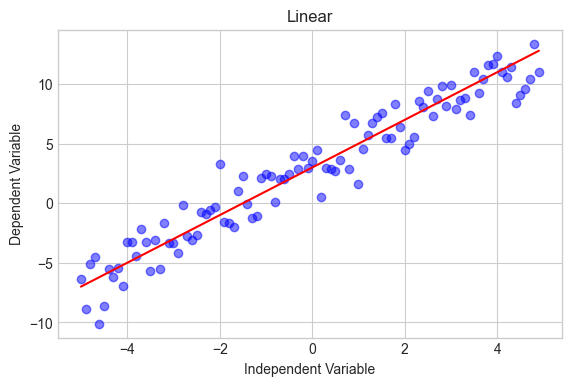

In [2]:
x = np.arange(-5.0, 5.0, 0.1)

y = 2 * x + 3
y_noise = 2 * rng.normal(size=x.size)
ydata = y + y_noise

plt.figure(figsize=(6.5, 4))
plt.plot(x, ydata, "bo", alpha=0.5)
plt.plot(x, y, "r")
plt.ylabel("Dependent Variable")
plt.xlabel("Independent Variable")
plt.title("Linear")
plt.show()

### Cubic

$y = a x^3 + b x^2 + c x + d$. The graph is no longer a straight line, so this is
a curved *shape* — though, as section 3 noted, it is still linear in its
parameters and can be fitted the lesson-03 way.

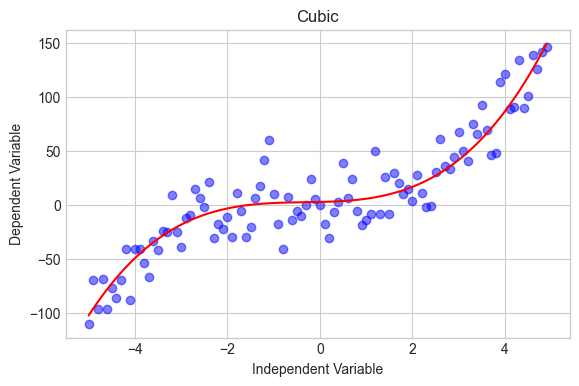

In [3]:
x = np.arange(-5.0, 5.0, 0.1)

y = 1 * (x**3) + 1 * (x**2) + 1 * x + 3
y_noise = 20 * rng.normal(size=x.size)
ydata = y + y_noise

plt.figure(figsize=(6.5, 4))
plt.plot(x, ydata, "bo", alpha=0.5)
plt.plot(x, y, "r")
plt.ylabel("Dependent Variable")
plt.xlabel("Independent Variable")
plt.title("Cubic")
plt.show()

### Quadratic

$Y = X^2$ — the simplest curve, symmetric about its minimum.

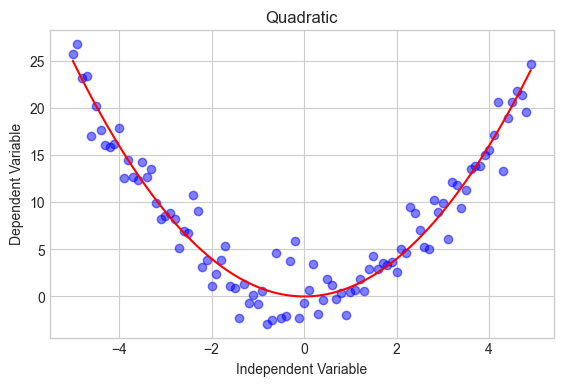

In [4]:
x = np.arange(-5.0, 5.0, 0.1)

y = np.power(x, 2)
y_noise = 2 * rng.normal(size=x.size)
ydata = y + y_noise

plt.figure(figsize=(6.5, 4))
plt.plot(x, ydata, "bo", alpha=0.5)
plt.plot(x, y, "r")
plt.ylabel("Dependent Variable")
plt.xlabel("Independent Variable")
plt.title("Quadratic")
plt.show()

### Exponential

$Y = a + b c^{X}$, with $b \neq 0$, $c > 0$ and $c \neq 1$. The base is constant
and the exponent is the variable — which is what makes growth accelerate without
limit.

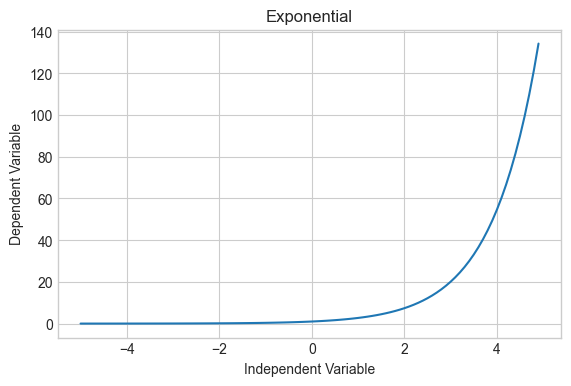

In [5]:
X = np.arange(-5.0, 5.0, 0.1)
Y = np.exp(X)

plt.figure(figsize=(6.5, 4))
plt.plot(X, Y)
plt.ylabel("Dependent Variable")
plt.xlabel("Independent Variable")
plt.title("Exponential")
plt.show()

### Logarithmic

$y = \log(x)$ — the inverse of exponential growth. It rises quickly at first and
then almost stops. It is undefined for $x \leq 0$, so the range below starts just
above zero.

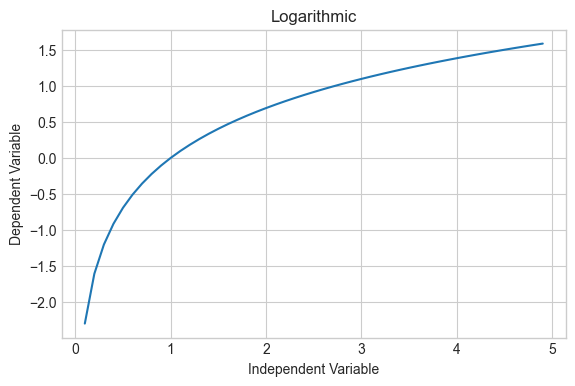

In [6]:
# Starting at 0.1 rather than -5: log is undefined for non-positive values, and
# asking for it produces NaNs and a runtime warning instead of a curve.
X = np.arange(0.1, 5.0, 0.1)
Y = np.log(X)

plt.figure(figsize=(6.5, 4))
plt.plot(X, Y)
plt.ylabel("Dependent Variable")
plt.xlabel("Independent Variable")
plt.title("Logarithmic")
plt.show()

### Sigmoidal / Logistic

$$Y = a + \frac{b}{1 + c^{(X - d)}}$$

Slow, then fast, then slow again, bounded at both ends. This is the shape that
matches the GDP series.

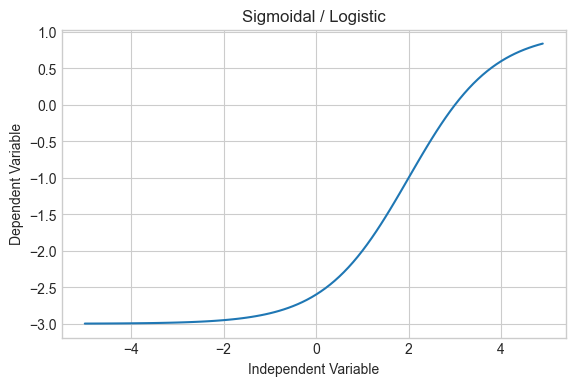

In [7]:
X = np.arange(-5.0, 5.0, 0.1)
Y = 1 - 4 / (1 + np.power(3, X - 2))

plt.figure(figsize=(6.5, 4))
plt.plot(X, Y)
plt.ylabel("Dependent Variable")
plt.xlabel("Independent Variable")
plt.title("Sigmoidal / Logistic")
plt.show()

### The GDP data

In [8]:
df = pd.read_csv("data/china_gdp.csv")
df.head(10)

,Year,Value
0,1960,5.918412e+10
1,1961,4.955705e+10
2,1962,4.668518e+10
3,1963,5.009730e+10
4,1964,5.906225e+10
5,1965,6.970915e+10
6,1966,7.587943e+10
7,1967,7.205703e+10
8,1968,6.999350e+10
9,1969,7.871882e+10


In [9]:
df.tail()

,Year,Value
50,2010,6.039659e+12
51,2011,7.492432e+12
52,2012,8.461623e+12
53,2013,9.490603e+12
54,2014,1.035483e+13


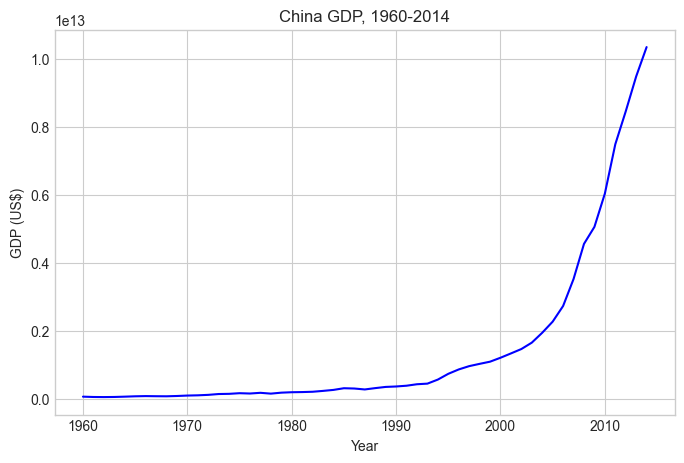

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(df.Year, df.Value, "b")
plt.xlabel("Year")
plt.ylabel("GDP (US$)")
plt.title("China GDP, 1960-2014")
plt.show()

The shape is unmistakable: near-flat growth through the 1960s and 1970s, a slow
climb through the 1980s and 1990s, a steep rise from about 2005, and a slight
deceleration in the 2010s.

That is either exponential or logistic. The difference is what happens at the
end — exponential growth never slows, while a logistic curve flattens toward a
ceiling. The visible tapering after 2010 is the reason to prefer the logistic.

## 5. Modeling

### Choosing a model

The logistic function has exactly the property the data shows: slow growth, then
rapid growth, then slowing again.

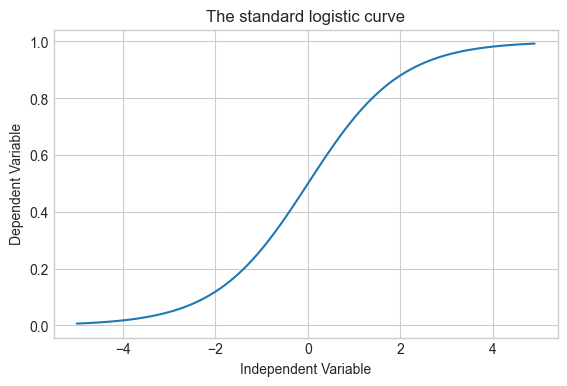

In [11]:
X = np.arange(-5.0, 5.0, 0.1)
Y = 1.0 / (1.0 + np.exp(-X))

plt.figure(figsize=(6.5, 4))
plt.plot(X, Y)
plt.ylabel("Dependent Variable")
plt.xlabel("Independent Variable")
plt.title("The standard logistic curve")
plt.show()

### Building the model

$$
\hat{Y} = \frac{1}{1 + e^{\beta_1 (X - \beta_2)}}
$$

$\beta_1$ controls the curve's steepness; $\beta_2$ slides it along the x-axis.

In [12]:
def sigmoid(x, Beta_1, Beta_2):
    y = 1 / (1 + np.exp(-Beta_1 * (x - Beta_2)))
    return y

A first look at whether a sigmoid can plausibly sit on this data, using
parameters picked by hand rather than fitted.

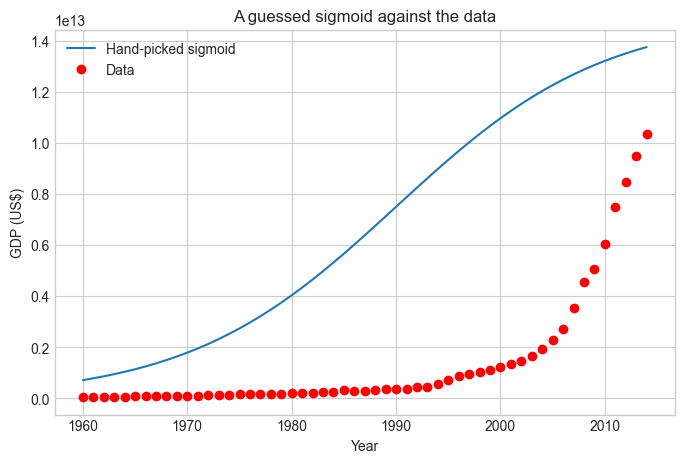

In [13]:
beta_1 = 0.10
beta_2 = 1990.0

x_data, y_data = (df["Year"].values, df["Value"].values)

# logistic function
Y_pred = sigmoid(x_data, beta_1, beta_2)

plt.figure(figsize=(8, 5))
# The sigmoid maxes out at 1, so it is scaled up to GDP magnitudes purely to
# make the comparison visible.
plt.plot(x_data, Y_pred * 15000000000000.0, label="Hand-picked sigmoid")
plt.plot(x_data, y_data, "ro", label="Data")
plt.xlabel("Year")
plt.ylabel("GDP (US$)")
plt.title("A guessed sigmoid against the data")
plt.legend()
plt.show()

Close enough in shape to be worth fitting properly.

### Normalising

Both axes are rescaled into the range 0–1 before fitting. Years run in the
thousands and GDP in the trillions, and an optimiser searching over raw values
like those takes steps that are wildly wrong for one axis or the other.
Normalising also matches the standard logistic, which saturates at 1.

In [14]:
# Lets normalize our data
xdata = x_data / max(x_data)
ydata = y_data / max(y_data)

### Finding the best parameters

`curve_fit` uses non-linear least squares: it searches for the parameters that
minimise the sum of the squared residuals between `sigmoid(xdata, *popt)` and
`ydata`. `popt` holds the optimised parameters.

In [15]:
from scipy.optimize import curve_fit

popt, pcov = curve_fit(sigmoid, xdata, ydata)

# print the final parameters
print(" beta_1 = %f, beta_2 = %f" % (popt[0], popt[1]))

 beta_1 = 690.451712, beta_2 = 0.997207


## 6. Results and interpretation

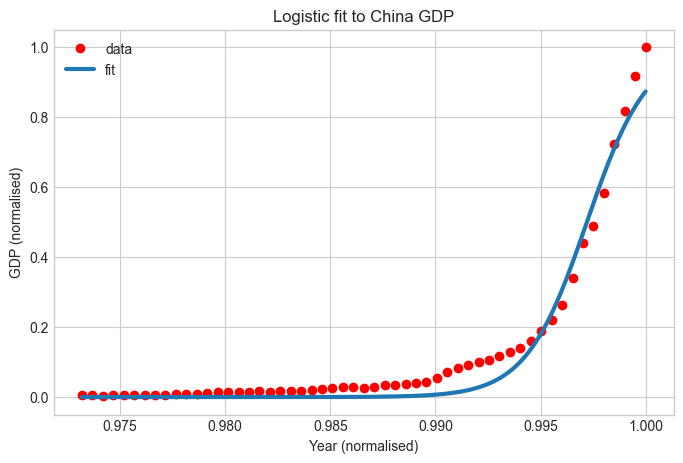

In [16]:
# Same divisor as xdata above. Normalising the line by 2015 while the data was
# normalised by 2014 draws the curve shifted sideways against its own points.
x_line = np.linspace(x_data.min(), x_data.max(), 200) / max(x_data)
y_line = sigmoid(x_line, *popt)

plt.figure(figsize=(8, 5))
plt.plot(xdata, ydata, "ro", label="data")
plt.plot(x_line, y_line, linewidth=3.0, label="fit")
plt.legend(loc="best")
plt.ylabel("GDP (normalised)")
plt.xlabel("Year (normalised)")
plt.title("Logistic fit to China GDP")

# Saved so README.md can show the result without anyone running this notebook.
plt.savefig("figures/result.png", dpi=150, bbox_inches="tight")
plt.show()

### Reading the result

The curve reproduces the overall shape — flat for decades, then a sharp turn
upward — from two parameters alone. A large fitted $\beta_1$ means that
transition is abrupt: on the normalised axis the curve turns over a very narrow
span, matching the takeoff after 2000.

But the fit is visibly imperfect, in a way worth understanding rather than
glossing over. Through the 1990s and early 2000s the curve sits *below* the
observed points, and at the right-hand end it undershoots the most recent years
noticeably — the final observation reaches 1.0 while the curve stops well short
of it.

The cause is the model, not the optimiser. This sigmoid has exactly two
parameters, steepness and position, and none for its ceiling: it saturates at
exactly 1.0 by construction. Since the data were normalised by their own
maximum, the last observation *is* 1.0 — so the curve is being asked to reach
its asymptote at the very last data point, which a logistic only does in the
limit. Least squares resolves the conflict by compromising, sitting low at the
end to avoid larger errors through the middle.

Adding a third parameter for the ceiling, fitting
$a / (1 + e^{-\beta_1 (x - \beta_2)})$ instead, would lift that constraint. The
two-parameter form is what the lesson teaches, and its limitation is visible in
the plot above.

**What this model does not justify.** The logistic shape asserts that growth
approaches a ceiling. That assumption came from the look of the curve, not from
economics, and the data stops in 2014 — barely past the point where the
flattening begins. Extrapolating to find *where* the ceiling sits would read far
more into two parameters than fifty-five points can support. The fit describes
the period it was given; it is not a forecast.

**On evaluation.** Unlike lessons 01–03, this model is fitted on every available
point and there is no held-out score. That is deliberate: with 55 annual
observations, a random train/test split would be the wrong instrument, because
holding out scattered years asks the model only to interpolate between
neighbours it has already seen — an easy task that flatters the result. The
meaningful test for a time series is temporal: fit on the earlier years, predict
the later ones. This notebook stops short of that, which is the obvious next step
for the lesson.

## 7. References

- Course: Machine Learning with Python (Jadi) — lesson on non-linear regression,
  which uses this dataset and framing.
- Dataset: China GDP 1960–2014, from the World Bank's world development
  indicators.
- SciPy documentation: [`scipy.optimize.curve_fit`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html)